# Can audio features identify Billboard hits?
Robyn Moore · Music analytics portfolio

A historical classification study using HSP-S. This notebook separates training, model and threshold selection, and final testing by release period. See the [case study](case-study.pdf) for the commercial interpretation.

## 1. Load the audio and release-year files
Download **hsp-s_acousticbrainz.parquet** and **hsp-s_uuid_year.csv** from [HSP-S on Zenodo](https://zenodo.org/records/5383858). Place them alongside this notebook. The analysis reads only the required columns. Chart position, release year, artist and UUID are used for labeling, splitting or diagnostics, and are excluded from the predictors.

In [1]:
import pandas as pd

# Select 12 musical features
features = [
    "rhythm.bpm",
    "rhythm.danceability",
    "lowlevel.average_loudness",
    "lowlevel.dynamic_complexity",
    "lowlevel.spectral_centroid.mean",
    "lowlevel.dissonance.mean",
    "lowlevel.pitch_salience.mean",
    "tonal.key_strength",
    "tonal.chords_changes_rate",
    "highlevel.mood_happy.all.happy",
    "highlevel.mood_sad.all.sad",
    "highlevel.mood_party.all.party"
]

artist_col = "metadata.tags.artist_hl"
audio = pd.read_parquet(
    "hsp-s_acousticbrainz.parquet",
    columns=["uuid", "peakPos", artist_col, *features],
    engine="pyarrow",
)
years = pd.read_csv("hsp-s_uuid_year.csv", usecols=["uuid", "year"])

print(f"Audio records: {len(audio):,}")
print(f"Release-year lookup rows: {len(years):,}")

Audio records: 7,736
Release-year lookup rows: 44,272


### 1.1 Check identifiers and chart-field coverage

Before combining files, check UUID uniqueness and how many audio records match the year lookup. The saved results show no duplicated UUIDs in either input, 7,449 matched audio records and 287 unmatched records.

The chart-field check also records 3,870 songs with a `peakPos` value and 3,866 without one. This is the full-file class distribution, before release-year exclusions.

In [2]:
# Check whether song IDs match across datasets

print("Unique audio IDs:", audio["uuid"].nunique())
print("Unique year IDs:", years["uuid"].nunique())

print("Duplicate audio IDs:", audio["uuid"].duplicated().sum())
print("Duplicate year IDs:", years["uuid"].duplicated().sum())

# Compare the IDs between the files
matching_ids = audio["uuid"].isin(years["uuid"])

print("Matching audio records:", matching_ids.sum())
print("Unmatched audio records:", (~matching_ids).sum())

# Inspect Billboard chart data
print("\nSongs with chart positions:",
      audio["peakPos"].notna().sum())

print("Songs without chart positions:",
      audio["peakPos"].isna().sum())

Unique audio IDs: 7736
Unique year IDs: 44272
Duplicate audio IDs: 0
Duplicate year IDs: 0
Matching audio records: 7449
Unmatched audio records: 287

Songs with chart positions: 3870
Songs without chart positions: 3866


## 2. Define the outcome and merge release years

The dataset paper defines chart hits by Billboard Hot 100 appearance and samples non-hits separately; chart fields are provided for hits [2, Sections III-A and IV-C]. This supports the following operational target:

| Target | Code rule | Meaning in this project |
|---|---|---|
| Hit = 1 | `peakPos.notna()` | A chart appearance is recorded in the benchmark. |
| Non-hit = 0 | `peakPos.isna()` | No chart appearance is recorded in the benchmark. |

This is a definition of chart status within a constructed dataset. A non-hit label does not establish that a song failed commercially or was unsuccessful in another territory or chart.

The merge is a left join on `uuid`, with `validate="one_to_one"` to protect the row count. Year, chart positions, chart weeks, last.fm counts, artist names and identifiers are excluded from the model inputs. `peakPos` is used only to construct the outcome.

In [3]:
# Join release years onto the audio dataset
df = audio.merge(
    years[["uuid", "year"]],
    on="uuid",
    how="left",
    validate="one_to_one"
)

# Create our classification target
df["is_hit"] = df["peakPos"].notna().astype(int)

print("Dataset shape:", df.shape)

print("\nHit distribution:")
print(df["is_hit"].value_counts())

print("\nMissing release years:")
print(df["year"].isna().sum())

print("\nPreview:")

Dataset shape: (7736, 1891)

Hit distribution:
is_hit
1    3870
0    3866
Name: count, dtype: int64

Missing release years:
287

Preview:


## 3. Select and check the musical features

Twelve numeric audio features are selected to cover rhythm, dynamics, spectral characteristics, pitch, tonality and mood. This is a compact feature set for the present experiment; the notebook does not establish that it is the best possible subset.

| Group | Selected columns |
|---|---|
| Rhythm | `rhythm.bpm`, `rhythm.danceability` |
| Dynamics | `lowlevel.average_loudness`, `lowlevel.dynamic_complexity` |
| Spectrum and pitch | `lowlevel.spectral_centroid.mean`, `lowlevel.dissonance.mean`, `lowlevel.pitch_salience.mean` |
| Tonality | `tonal.key_strength`, `tonal.chords_changes_rate` |
| Mood scores | `highlevel.mood_happy.all.happy`, `highlevel.mood_sad.all.sad`, `highlevel.mood_party.all.party` |

The mood features are outputs of pretrained audio classifiers [2, Section III-C]. They should not be read as direct observations of listener emotion.

All 12 selected columns are present, numeric and have zero missing values in the saved check. No feature imputation is performed. This check does not constitute a full audit for outliers, extraction artefacts or infinite values.

In [4]:
# Check that the columns exist
available = [col for col in features if col in df.columns]
missing = [col for col in features if col not in df.columns]

print("Available features:", len(available))
print("Missing feature names:", missing)

# Examine data completeness and types
feature_check = pd.DataFrame({
    "Data type": df[available].dtypes.astype(str),
    "Missing values": df[available].isna().sum(),
    "Missing %": (
        df[available].isna().mean() * 100
    ).round(2)
})

display(feature_check)

Available features: 12
Missing feature names: []


                                Data type  Missing values  Missing %
rhythm.bpm                        float64               0        0.0
rhythm.danceability               float64               0        0.0
lowlevel.average_loudness         float64               0        0.0
lowlevel.dynamic_complexity       float64               0        0.0
lowlevel.spectral_centroid.mean   float64               0        0.0
lowlevel.dissonance.mean          float64               0        0.0
lowlevel.pitch_salience.mean      float64               0        0.0
tonal.key_strength                float64               0        0.0
tonal.chords_changes_rate         float64               0        0.0
highlevel.mood_happy.all.happy    float64               0        0.0
highlevel.mood_sad.all.sad        float64               0        0.0
highlevel.mood_party.all.party    float64               0        0.0

## 4. Audit release years and sample composition

The saved release-year range is 1928 to 2010, with 287 songs missing a matched year. The decade table shows that class balance varies substantially across release periods, even though the original file is almost evenly split between hits and non-hits.

The analysis uses 1960-2009 to focus on five complete decades with substantially larger samples than the earlier years or the single year 2010. These are release years, not first-chart-entry dates.

In [5]:
# Check the range of release years
print("Earliest release year:", df["year"].min())
print("Latest release year:", df["year"].max())

# Group songs by decade
df["decade"] = (df["year"] // 10 * 10)

# Count hits and non-hits by decade
decade_summary = pd.crosstab(
    df["decade"],
    df["is_hit"]
)

decade_summary.columns = ["Non-Hits", "Hits"]
decade_summary["Total"] = decade_summary.sum(axis=1)

display(decade_summary)

# Check how many songs are missing a release year
print("Songs missing release years:", df["year"].isna().sum())


Earliest release year: 1928.0
Latest release year: 2010.0


        Non-Hits  Hits  Total
decade                       
1920.0         3     0      3
1930.0         1     0      1
1940.0         1     1      2
1950.0        47    45     92
1960.0       138   495    633
1970.0       283   718   1001
1980.0       448   825   1273
1990.0      1235   726   1961
2000.0      1621   792   2413
2010.0        59    11     70

Songs missing release years: 287


### 4.1 Missing release years are associated with the outcome

The 287 songs without a matched year have an **89.55% hit rate**, compared with **48.50%** among the 7,449 songs with known years. Removing these records therefore changes the class mix. The available check establishes an association between year availability and the target; it does not explain the missingness mechanism.

Missing-year records cannot be placed reliably in a chronological split, so they are preserved separately rather than assigned an invented year.

In [6]:
# Compare songs with and without release years
year_check = df.groupby(
    df["year"].isna()
)["is_hit"].agg(["count", "sum", "mean"])

year_check.index = [
    "Release year available",
    "Release year missing"
]

year_check.columns = [
    "Total Songs",
    "Billboard Hits",
    "Hit Rate"
]

year_check["Hit Rate"] = (
    year_check["Hit Rate"] * 100
).round(2)

display(year_check)


                        Total Songs  Billboard Hits  Hit Rate
Release year available         7449            3613     48.50
Release year missing            287             257     89.55

### 4.2 Preserve excluded records

The next cell creates `missing_year_df` and `known_year_df` and confirms that their combined row count remains 7,736. All modelling uses known-year records only.

In [7]:
# Set aside songs with missing release years
missing_year_df = df[df["year"].isna()].copy()

# Keep songs with known release years
known_year_df = df[df["year"].notna()].copy()

# Confirm the records are preserved
print("Original dataset:", len(df))
print("Known release years:", len(known_year_df))
print("Missing release years:", len(missing_year_df))

print("\nTotal records accounted for:",
      len(known_year_df) + len(missing_year_df))


Original dataset: 7736
Known release years: 7449
Missing release years: 287

Total records accounted for: 7736


## 5. Split training, validation and test data by release year

The chronological split keeps older releases in training and later releases in evaluation. Validation is used to choose the model and threshold; the test set is reserved for the final evaluation.

| Partition | Release years | Songs | Hits | Non-hits | Hit rate |
|---|---|---:|---:|---:|---:|
| Training | 1960-1989 | 2,907 | 2,038 | 869 | 70.11% |
| Validation | 1990-1999 | 1,961 | 726 | 1,235 | 37.02% |
| Test | 2000-2009 | 2,413 | 792 | 1,621 | 32.82% |
| Total | 1960-2009 | 7,281 | 3,556 | 3,725 | 48.84% |

**Record accounting:** 7,736 original songs - 287 missing years - 168 known-year songs outside 1960-2009 = 7,281 modelling songs. The assertions confirm unique and non-overlapping song UUIDs across partitions.

The shift from 70.11% hits in training to 32.82% in testing is a major sample-composition issue. It is not an estimate of the proportion of all released songs that became hits in those decades.

In [8]:
# Select songs released between 1960 and 2009
model_df = known_year_df[
    known_year_df["year"].between(1960, 2009)
].copy()

# Split the dataset chronologically
train_df = model_df[
    model_df["year"] <= 1989
].copy()

val_df = model_df[
    model_df["year"].between(1990, 1999)
].copy()

test_df = model_df[
    model_df["year"] >= 2000
].copy()

# Review each dataset
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(
        f"{name}: {len(data)} songs | "
        f"Hit rate: {data['is_hit'].mean():.2%}"
    )

print("\nTotal modelling records:", len(model_df))

# Confirm that songs do not overlap between groups
assert train_df["uuid"].is_unique
assert val_df["uuid"].is_unique
assert test_df["uuid"].is_unique

assert set(train_df["uuid"]).isdisjoint(val_df["uuid"])
assert set(train_df["uuid"]).isdisjoint(test_df["uuid"])
assert set(val_df["uuid"]).isdisjoint(test_df["uuid"])

print("No overlapping song IDs between datasets.")


Training: 2907 songs | Hit rate: 70.11%
Validation: 1961 songs | Hit rate: 37.02%
Testing: 2413 songs | Hit rate: 32.82%

Total modelling records: 7281
No overlapping song IDs between datasets.


### 5.1 Inspect artist metadata

Song IDs are separate across partitions, but an artist can release multiple songs in different decades. Artist metadata is inspected to assess this possible source of dependence. Artist names are not predictors.

In [9]:
# Inspect artist information in our datasets
artist_col = "metadata.tags.artist_hl"

print("Artist column available:", artist_col in df.columns)

print("\nMissing artist information:")
print("Training:", train_df[artist_col].isna().sum())
print("Validation:", val_df[artist_col].isna().sum())
print("Testing:", test_df[artist_col].isna().sum())

Artist column available: True

Missing artist information:
Training: 0
Validation: 0
Testing: 0


### 5.2 Measure artist overlap

Artist-list values are converted to case-normalised sets before comparison. The saved checks report **310 artists shared by training and validation**, and **148 shared by training and testing**. In the test set, **236 songs (9.78%)** contain an artist also present in training.

This experiment is not artist-disjoint. Audio can retain artist-specific characteristics even when artist names are excluded, so the results should not be described as performance solely on new artists. The check uses text names and does not resolve aliases or every collaboration. Test overlap with validation artists is not reported in the current analysis.

In [10]:

import numpy as np

artist_col = "metadata.tags.artist_hl"

# Convert artist lists into consistent sets of names
def get_artists(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        names = value
    else:
        names = [value]

    return {
        str(name).strip().casefold()
        for name in names
        if name is not None and str(name).strip()
    }

# Find all artists represented in each dataset
train_artists = set().union(
    *(get_artists(x) for x in train_df[artist_col])
)

val_artists = set().union(
    *(get_artists(x) for x in val_df[artist_col])
)

test_artists = set().union(
    *(get_artists(x) for x in test_df[artist_col])
)

# Check artist overlap
print("Unique training artists:", len(train_artists))
print("Unique validation artists:", len(val_artists))
print("Unique testing artists:", len(test_artists))

print("\nArtists shared between periods:")
print("Training & validation:",
      len(train_artists & val_artists))

print("Training & testing:",
      len(train_artists & test_artists))

# Check how many test songs feature earlier artists
seen_test_songs = test_df[artist_col].apply(
    lambda x: bool(get_artists(x) & train_artists)
)

print("\nTest songs featuring training-period artists:",
      seen_test_songs.sum())

print("Percentage of test songs:",
      f"{seen_test_songs.mean():.2%}")


Unique training artists: 1273
Unique validation artists: 1116
Unique testing artists: 1312

Artists shared between periods:
Training & validation: 310
Training & testing: 148

Test songs featuring training-period artists: 236
Percentage of test songs: 9.78%


## 6. Fit a baseline and Logistic Regression

`DummyClassifier(strategy="most_frequent")` learns the majority class from training. Training contains more hits, so this fitted baseline predicts **hit for every validation song**, giving 37.0% accuracy and 50.0% balanced accuracy.

Logistic Regression provides a linear comparison. `StandardScaler` is inside a pipeline and is fitted on training features only. Validation data are transformed using those training-derived statistics. The fitted model uses `max_iter=3000` and `random_state=42`.

### How the metrics are used

- **Accuracy:** proportion of all predictions that are correct; it depends on the class mix.
- **Balanced accuracy:** average of hit recall and non-hit recall; the threshold-selection objective.
- **Hit precision:** fraction of predicted hits that are actual hits.
- **Hit recall:** fraction of actual hits that the model identifies.
- **F1:** harmonic mean of hit precision and hit recall.
- **ROC-AUC:** ranking discrimination across thresholds; 0.5 is the constant-score benchmark. It is not a probability calibration measure.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Separate musical features from our target
X_train = train_df[features]
y_train = train_df["is_hit"]

X_val = val_df[features]
y_val = val_df["is_hit"]

# Model 1: Simple baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

# Model 2: Logistic Regression
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=42)
)
log_model.fit(X_train, y_train)

# Evaluate both models on validation data
results = []

for name, model in [
    ("Baseline", baseline),
    ("Logistic Regression", log_model)
]:
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))


                 Model  Accuracy  Balanced Accuracy  Precision  Recall     F1  \
0             Baseline     0.370              0.500       0.37   1.000  0.540   
1  Logistic Regression     0.457              0.556       0.40   0.937  0.561   

   ROC-AUC  
0    0.500  
1    0.633  

### 6.1 Compare Random Forest on the same validation set

Random Forest is fitted on training data only, using 200 trees, maximum depth 8, minimum leaf size 5 and `random_state=42`. There is no broad hyperparameter search in the notebook.

At the default classification threshold, Random Forest has validation ROC-AUC **0.670**, compared with **0.633** for Logistic Regression and **0.500** for the baseline. Its balanced accuracy is **0.570**. On this evidence, Random Forest is selected for threshold exploration.

Random Forest initially predicts 87.46% of validation songs as hits, although only 37.02% are labelled hits. This motivates checking the decision threshold using validation data.

In [12]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest using training data only
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predict on validation data
rf_predictions = rf_model.predict(X_val)
rf_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Evaluate the model
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_val, rf_predictions),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, rf_predictions
    ),
    "Precision": precision_score(
        y_val, rf_predictions, zero_division=0
    ),
    "Recall": recall_score(y_val, rf_predictions),
    "F1": f1_score(y_val, rf_predictions),
    "ROC-AUC": roc_auc_score(
        y_val, rf_probabilities
    )
}

# Compare all three models
comparison_df = pd.concat([
    results_df,
    pd.DataFrame([rf_results])
], ignore_index=True)

display(comparison_df.round(3))

print(
    "Random Forest predicted hit rate:",
    f"{rf_predictions.mean():.2%}"
)


                 Model  Accuracy  Balanced Accuracy  Precision  Recall     F1  \
0             Baseline     0.370              0.500      0.370   1.000  0.540   
1  Logistic Regression     0.457              0.556      0.400   0.937  0.561   
2        Random Forest     0.468              0.570      0.408   0.963  0.573   

   ROC-AUC  
0    0.500  
1    0.633  
2    0.670  

Random Forest predicted hit rate: 87.46%


## 7. Choose a classification threshold on validation data

Thresholds from 0.30 to 0.90 are evaluated in increments of 0.05. A song is assigned to the hit class when its Random Forest score meets or exceeds the threshold.

The best **balanced accuracy among these tested thresholds** occurs at **0.65**: validation balanced accuracy **0.626**, accuracy **0.595**, hit precision **0.470** and hit recall **0.745**. The 0.75 threshold gives higher accuracy (0.650), but lower balanced accuracy (0.592) and recall (0.369).

The selected threshold reflects the stated objective of recognising both classes. It is not shown to maximise revenue or reflect an A&R team's costs. A 0.65 model score should not be interpreted as a verified 65% real-world chance of chart success.

In [13]:
import numpy as np

# Compare classification thresholds
threshold_results = []

for threshold in np.arange(0.30, 0.91, 0.05):

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Predicted Hit Rate": predictions.mean()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

# Identify the best threshold by balanced accuracy
best_row = threshold_df.loc[
    threshold_df["Balanced Accuracy"].idxmax()
]

print(
    "\nBest threshold (balanced accuracy):",
    round(best_row["Threshold"], 2)
)

print(
    "Best balanced accuracy:",
    round(best_row["Balanced Accuracy"], 3)
)


    Threshold  Accuracy  Balanced Accuracy  Precision  Recall     F1  \
0        0.30     0.392              0.517      0.378   0.999  0.549   
1        0.35     0.402              0.525      0.382   0.997  0.553   
2        0.40     0.418              0.537      0.388   0.994  0.558   
3        0.45     0.438              0.550      0.396   0.983  0.564   
4        0.50     0.468              0.570      0.408   0.963  0.573   
5        0.55     0.514              0.596      0.427   0.913  0.582   
6        0.60     0.549              0.606      0.442   0.828  0.576   
7        0.65     0.595              0.626      0.470   0.745  0.576   
8        0.70     0.625              0.616      0.494   0.584  0.535   
9        0.75     0.650              0.592      0.539   0.369  0.438   
10       0.80     0.639              0.534      0.558   0.127  0.207   
11       0.85     0.630              0.502      0.556   0.007  0.014   
12       0.90     0.630              0.500      0.000   0.000  0


Best threshold (balanced accuracy): 0.65
Best balanced accuracy: 0.626


### 7.1 Read the validation confusion matrix

At the selected threshold, validation predictions comprise 625 correct non-hits, 610 false alarms, 185 missed hits and 541 correct hits. The model captures 74.5% of validation hits but correctly rejects only 50.6% of validation non-hits.

The following matrix describes the validation sample used to select the threshold, so it is not an independent final performance estimate.

True Negatives: 625
False Positives: 610
False Negatives: 185
True Positives: 541


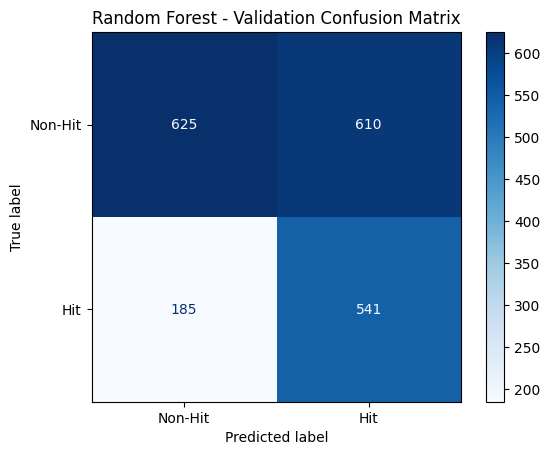

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Apply our selected validation threshold
best_threshold = float(best_row["Threshold"])

final_val_predictions = (
    rf_probabilities >= best_threshold
).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(
    y_val,
    final_val_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Visualize the results
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Hit", "Hit"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Validation Confusion Matrix")
plt.show()

## 8. Evaluate the frozen model on the test set

The original Random Forest remains fitted on 1960-1989 songs. It is not refitted on the validation set. The threshold remains fixed at **0.65**, and predictions are evaluated on 2000-2009 releases.

| Test metric | Random Forest at 0.65 |
|---|---:|
| Accuracy | 61.3% |
| Balanced accuracy | 63.6% |
| Hit precision | 44.3% |
| Hit recall | 70.3% |
| F1 | 0.544 |
| ROC-AUC | 0.678 |

The test set contains 32.82% hits, while the model predicts 52.05% of songs as hits. Results rounded here follow the saved outputs; the predicted-positive percentage is calculated from the saved confusion-matrix counts.

### Compare baselines fairly

The training-fitted dummy continues to predict hits and would achieve 32.8% test accuracy and 50.0% balanced accuracy. The separate **always non-hit reference** achieves **67.2% accuracy**, **50.0% balanced accuracy** and **zero hit recall**. Its test accuracy is computed from the observed test class mix; it is not a separately tuned predictive model.

Random Forest improves recognition of both classes, as measured by balanced accuracy, but its overall accuracy is lower than the always non-hit reference. Both facts belong in the conclusion.

In [15]:
from sklearn.metrics import classification_report

# Prepare the unseen test dataset
X_test = test_df[features]
y_test = test_df["is_hit"]

# Use our existing trained model
test_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected on validation data
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Evaluate final model performance
print("FINAL TEST RESULTS")
print("------------------")

print("Accuracy:",
      round(accuracy_score(y_test, test_predictions), 3))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, test_predictions), 3))

print("Precision:",
      round(precision_score(y_test, test_predictions), 3))

print("Recall:",
      round(recall_score(y_test, test_predictions), 3))

print("F1:",
      round(f1_score(y_test, test_predictions), 3))

print("ROC-AUC:",
      round(roc_auc_score(y_test, test_probabilities), 3))

print("\nPredicted Hit Rate:",
      round(test_predictions.mean(), 3))

print("\nDetailed Classification Report:")
print(classification_report(y_test, test_predictions))

# Compare against a simple non-hit prediction
print("\nAlways predict non-hit accuracy:",
      round((y_test == 0).mean(), 3))

FINAL TEST RESULTS
------------------
Accuracy: 0.613
Balanced Accuracy: 0.636
Precision: 0.443
Recall: 0.703
F1: 0.544
ROC-AUC: 0.678

Predicted Hit Rate: 0.521

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.57      0.66      1621
           1       0.44      0.70      0.54       792

    accuracy                           0.61      2413
   macro avg       0.62      0.64      0.60      2413
weighted avg       0.68      0.61      0.62      2413


Always predict non-hit accuracy: 0.672


## 9. Examine validation permutation importance

Permutation importance shuffles one feature at a time in validation data and measures the mean decrease in ROC-AUC across ten repeats. This explains the fitted Random Forest; it does not change the model or threshold.

The largest reported decreases are happy mood score (**0.0273**), dynamic complexity (**0.0215**), dissonance (**0.0168**), sad mood score (**0.0160**) and chord change rate (**0.0152**).

These values describe the model's reliance on features in this validation sample. They do not establish causation or the direction of a relationship. In particular, this analysis does not show that increasing happiness, sadness or dissonance makes a song more successful. Correlated inputs can affect the rankings. The small negative value for key strength (-0.0003) is consistent with no useful measured contribution here; uncertainty intervals were not reported.

                            Feature  Importance
9    highlevel.mood_happy.all.happy      0.0273
3       lowlevel.dynamic_complexity      0.0215
5          lowlevel.dissonance.mean      0.0168
10       highlevel.mood_sad.all.sad      0.0160
8         tonal.chords_changes_rate      0.0152
0                        rhythm.bpm      0.0150
4   lowlevel.spectral_centroid.mean      0.0111
1               rhythm.danceability      0.0069
2         lowlevel.average_loudness      0.0051
6      lowlevel.pitch_salience.mean      0.0033
11   highlevel.mood_party.all.party      0.0014
7                tonal.key_strength     -0.0003

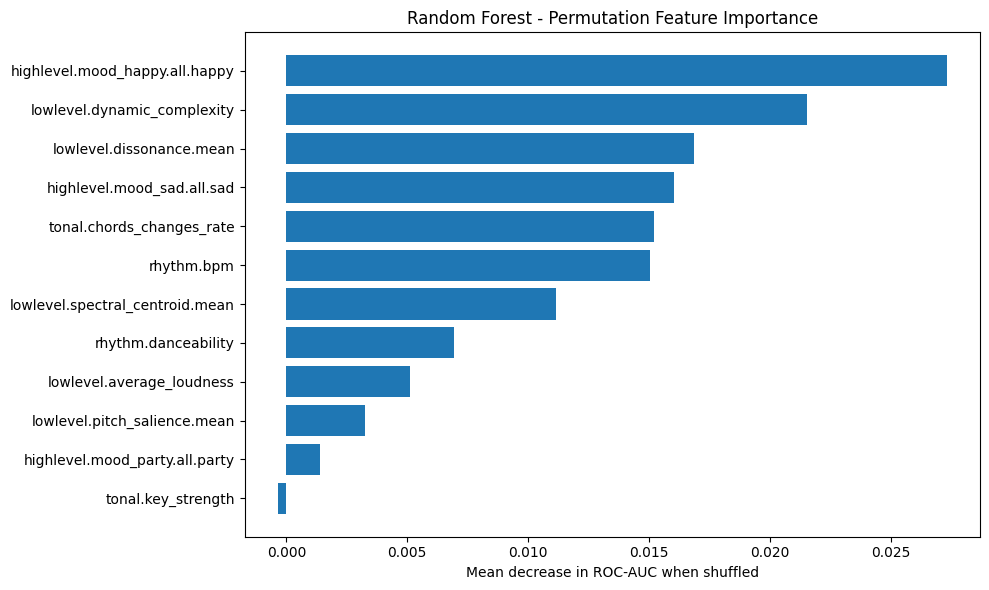

In [16]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate feature importance using validation data
importance = permutation_importance(
    rf_model,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance.importances_mean
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.round(4))

# Visualize the results
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Mean decrease in ROC-AUC when shuffled")
plt.title("Random Forest - Permutation Feature Importance")
plt.tight_layout()
plt.show()


## 10. Visualise final test errors

The saved test confusion matrix contains **922 true negatives**, **699 false positives**, **235 false negatives** and **557 true positives**. These sum to 2,413 songs and reproduce the saved classification metrics after rounding.

In practical terms, the model identifies 557 of 792 labelled hits but flags 699 non-hits as hits. Of its 1,256 hit predictions, about 44% are correct. This error profile is relevant when considering how much human review a shortlist would require.

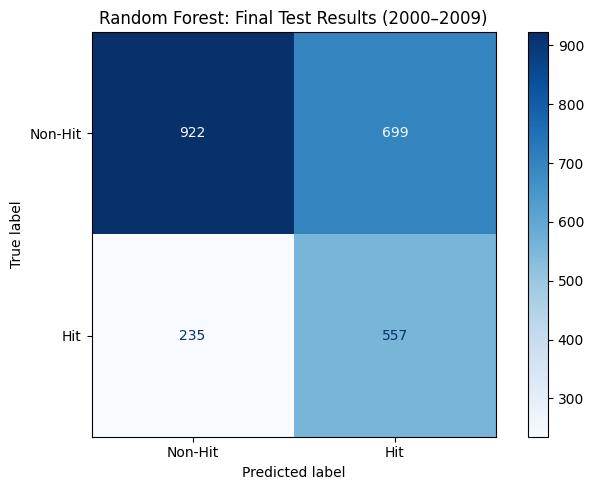

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Visualize final test predictions
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Non-Hit", "Hit"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Random Forest: Final Test Results (2000–2009)"
)

plt.tight_layout()
plt.show()


## 11. Findings and commercial interpretation

The selected audio features carry a modest signal for historical chart status in HSP-S. Random Forest ranks test songs better than a constant score (ROC-AUC 0.678), and the validation-selected threshold gives 63.6% balanced accuracy. However, 44.3% hit precision and 699 false alarms show the limits of using these predictions to prioritise investment.

For a music analytics team, the useful output of this project is evidence about model performance, changing sample composition and the limits of audio-only signals. The experiment does not validate an automatic signing, release-budget or campaign-selection tool. Artist context, audience evidence and commercial inputs would need their own evaluation, with data available at the decision date.

## 12. Limitations

1. **Constructed benchmark:** Hit and non-hit sampling means neither the overall class mix nor the decade-level hit rates represent all music releases. Matching or coverage errors may affect labels.
2. **Release-year split is not a strict historical forecast:** The source chart window extends to 6 July 2019 [2, Section III-A]. Lifetime chart status may be observed after a song's release period. The split therefore tests retrospective cross-era classification, not point-in-time forecasting.
3. **Changing class mix:** Training, validation and test hit rates differ greatly. Changing audio characteristics may also matter, but this notebook does not separate their effects.
4. **Non-random exclusion:** The 287 missing-year songs are much more hit-heavy than known-year songs. Their omission narrows the population covered by the conclusions.
5. **Repeated artists:** Artist overlap remains across time partitions, so performance on unseen artists has not been established.
6. **Limited evaluation:** One release-year split and one Random Forest configuration are evaluated. There are no confidence intervals, calibration checks, PR-AUC results or statistical model comparisons. Feature importance is descriptive and based on validation data.
7. **Historical and incomplete commercial scope:** Test releases end in 2009; current release campaigns, other charts, audience development and profitability are outside the target.

## 13. Recommended next experiments

- Freeze this result as the completed baseline. Any further tuning after seeing these test results requires a new untouched evaluation period or another prespecified evaluation design.
- Evaluate several rolling release-year windows and an artist-disjoint sensitivity analysis to measure stability.
- Report precision-recall curves, PR-AUC and uncertainty intervals. Select a threshold against a stated review capacity or business cost using development data only.
- Check score calibration and assess whether methods addressing changing class balance help in later periods.
- For an actual pre-release forecasting task, assemble point-in-time inputs and a fixed chart-outcome horizon, then compare audio with permitted pre-release context.

## 14. Reproduction and evidence notes

1. Download `hsp-s_acousticbrainz.parquet` and `hsp-s_uuid_year.csv` from [the dataset release](https://doi.org/10.5281/zenodo.5383858) and place them beside the notebook (or update both input paths).
2. Use Python with `pandas`, `numpy`, `scikit-learn`, `matplotlib` and a parquet engine such as `pyarrow`. The original notebook records Python 3 but does not pin package versions.
3. Run the code cells in order in Jupyter or Colab. The author-supplied rerun contains sequential execution counts 1-17, with no saved errors.
4. Check the input count (7,736), model sample (7,281), split sizes (2,907 / 1,961 / 2,413), threshold (0.65) and saved metric summaries before comparing results.

All modelling code and outputs in this version are preserved from the author-supplied rerun. Its displayed numerical outputs and chart images match the earlier version. Additional percentages and baseline comparisons in the narrative are arithmetic derived from the saved counts. The report's charts redraw these summaries. The reviewer verified the supplied rerun and did not independently execute the source datasets.

## References

[1] Vötter, M., Mayerl, M., Specht, G. and Zangerle, E. (2021). *Novel Datasets for Evaluating Song Popularity Prediction Tasks* [HSP-S / HSP-L dataset]. Zenodo. [Dataset DOI](https://doi.org/10.5281/zenodo.5383858). Input files are listed in the release.

[2] Vötter, M., Mayerl, M., Specht, G. and Zangerle, E. (2021). *Novel Datasets for Evaluating Song Popularity Prediction Tasks*. IEEE International Symposium on Multimedia, pp. 166-173. [Paper DOI](https://doi.org/10.1109/ISM52913.2021.00034); [author-hosted paper](https://evazangerle.at/publication/voetter-ism-2021/voetter-ism-2021.pdf). Sections III-A, III-C and IV-C support the chart-label definition, provenance and feature context.

[3] Project evidence: the supplied `Project_5 (1).ipynb`, 17 code cells with sequential execution counts 1-17, reviewed on 22 October 2026. Rerun outputs are the source for all reported project performance.